# Top-view image

In [6]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import itertools
import numpy as np
import math

In [19]:
DATA_DIR = Path("./../data")
# IMAGE_PATH = DATA_DIR / "development_set/8t_png.rf.a49c210a8d59660de79ffdb07d55a6f6.jpg"


IMAGE_PATH = DATA_DIR / "development_set/3f_png.rf.81c7e132365ef95bb19380ca389025f6.jpg"

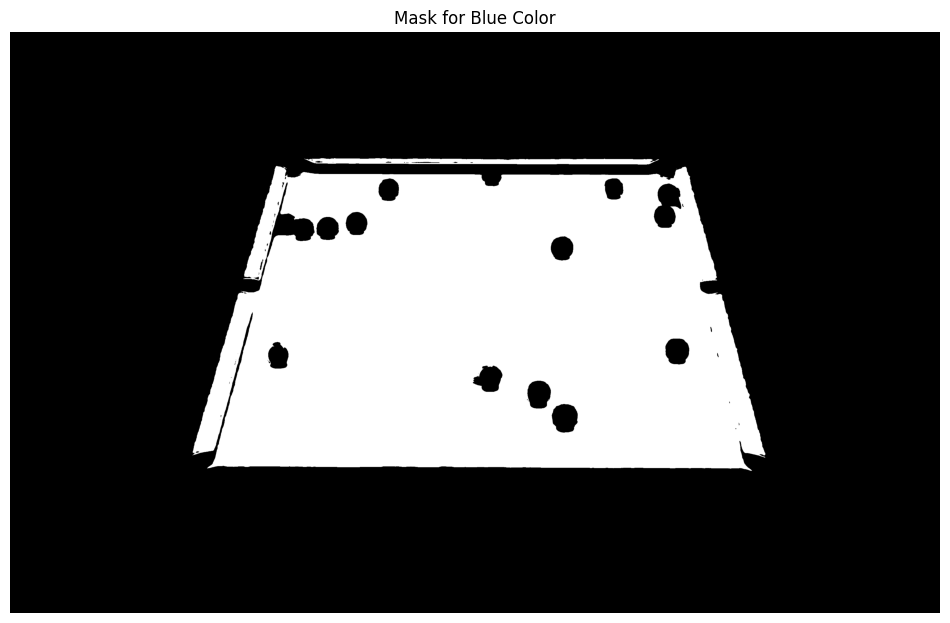

In [20]:
image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply Gaussian
image = cv2.GaussianBlur(image, (15, 15), 0)

# Mask Blue cloth
hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

lower_blue = np.array([200/2, 60 / 100 * 255, 60 / 100 * 255])
upper_blue = np.array([210/2, 110 / 100 * 255, 110 / 100 * 255])

mask_table = cv2.inRange(hsv_image, lower_blue, upper_blue)

plt.figure(figsize=(12, 8))
plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title('Mask for Blue Color')
plt.show()

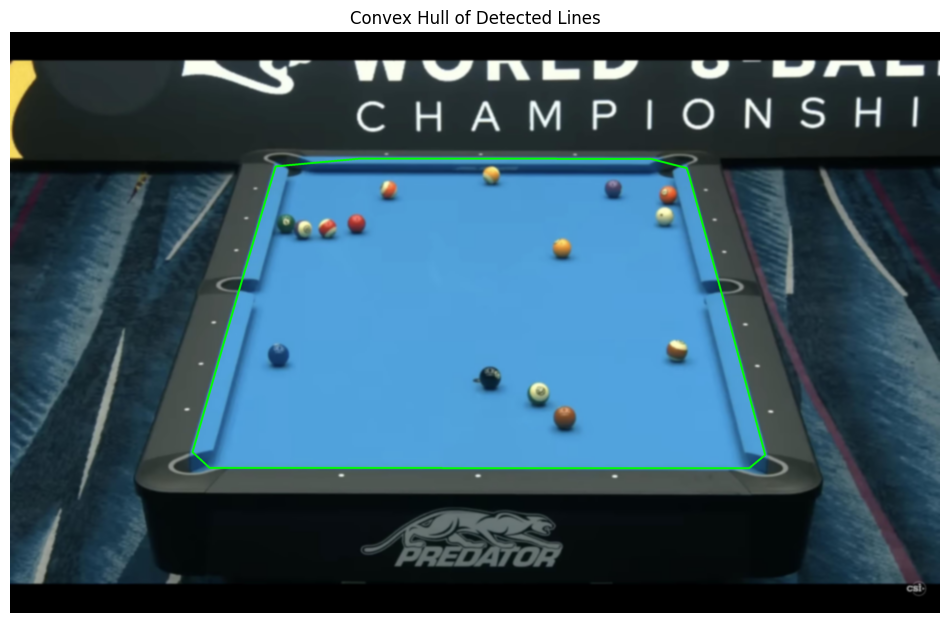

In [21]:
edges = cv2.Canny(mask_table, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=80
)

tmp_lines = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    if length >= 250:
        tmp_lines.append(line)
lines = tmp_lines

pts = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    pts.append((x1, y1))
    pts.append((x2, y2))

pts = np.array(pts)
hull = cv2.convexHull(pts)

line_image = image.copy()
cv2.polylines(line_image, [hull], isClosed=True, color=(0, 255, 0), thickness=5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Convex Hull of Detected Lines')
plt.show()

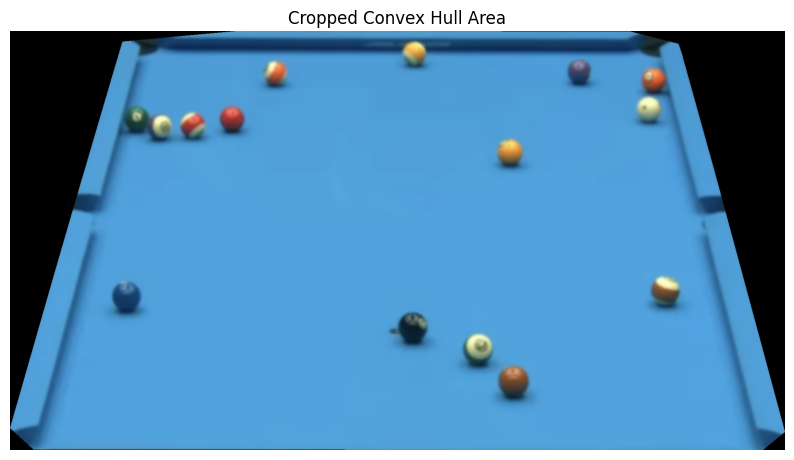

In [22]:
# 1. Create a black mask the same size as the image
mask = np.zeros(image.shape, dtype=np.uint8)

# 2. Fill the convex hull area with white
cv2.fillPoly(mask, [hull], (255, 255, 255))

# 3. Apply the mask to the original image
masked_image = cv2.bitwise_and(image, mask)

# 4. Crop to the bounding rectangle of the hull to remove black padding
x, y, w, h = cv2.boundingRect(hull)
final_crop = masked_image[y:y+h, x:x+w]

# Display result
plt.figure(figsize=(10, 6))
plt.imshow(final_crop)
plt.title('Cropped Convex Hull Area')
plt.axis('off')
plt.show()



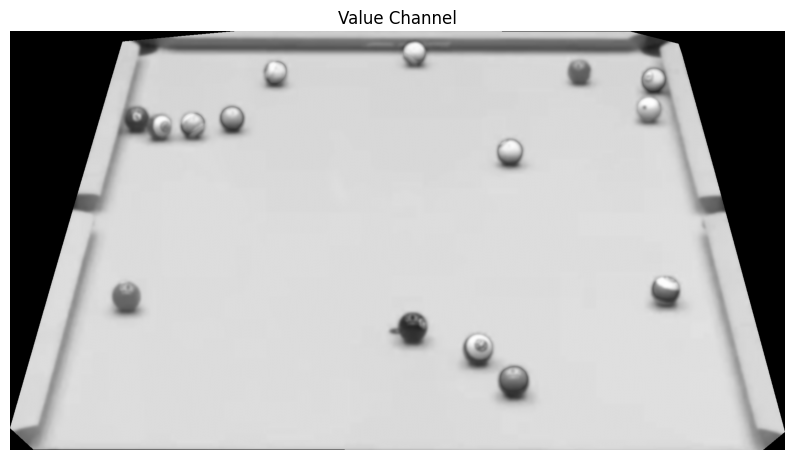

In [23]:
hsv_crop = cv2.cvtColor(final_crop, cv2.COLOR_RGB2HSV)
hsv_crop_c3 =hsv_crop[:, :, 2]
plt.figure(figsize=(10, 6))
plt.imshow(hsv_crop_c3, cmap='gray')
plt.title('Value Channel')
plt.axis('off')
plt.show()

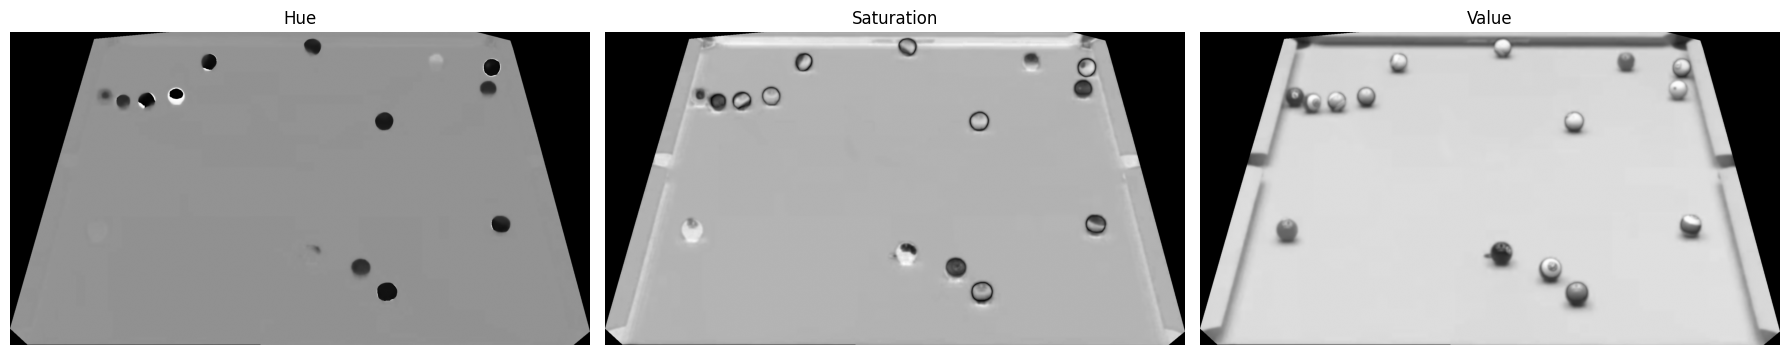

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (ax, title) in enumerate(zip(axes, ['Hue', 'Saturation', 'Value'])):
    ax.imshow(hsv_crop[:,:,i], cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

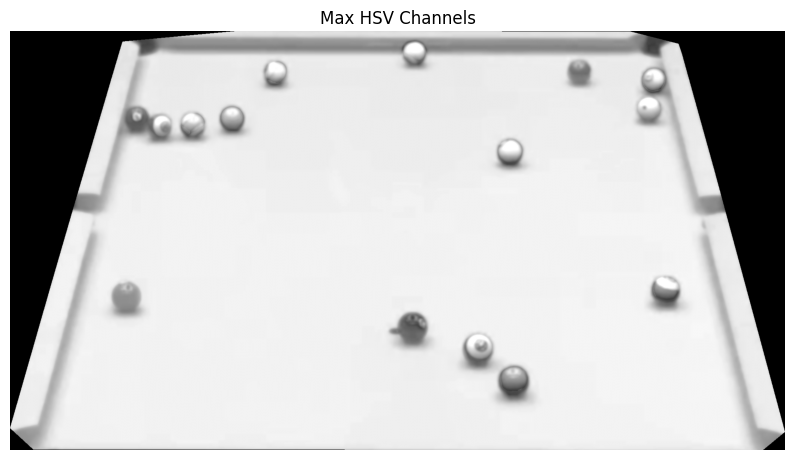

In [25]:
combined = np.maximum(hsv_crop[:,:,0], hsv_crop[:,:,1]) #some balls on visible on hue, saturation, value channels take the max of each
combined = np.maximum(combined, hsv_crop[:,:,2])

combined=   (0.3*combined + 0.8 * hsv_crop[:,:,2]).clip(0, 255).astype(np.uint8) #try to do weighted sums of the 3 channels

plt.figure(figsize=(10, 6))
plt.imshow(combined, cmap='gray')
plt.title('Max HSV Channels')
plt.axis('off')
plt.show()

Balls detected: 15


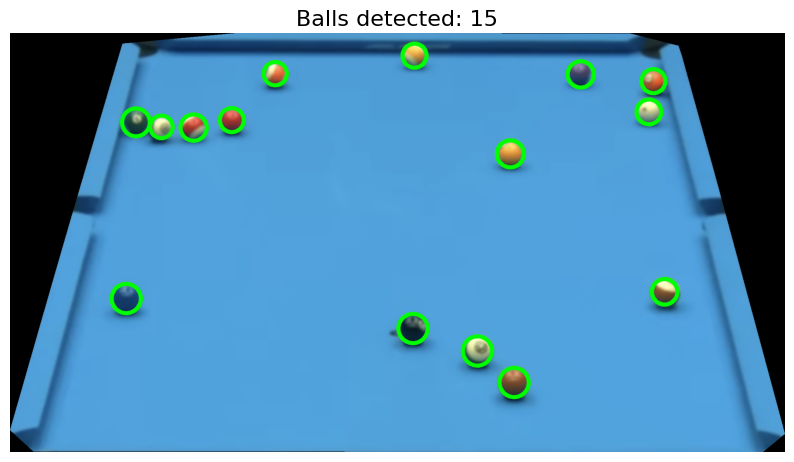

In [28]:
circles = cv2.HoughCircles(
    combined,        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=25,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=20,          # accumulator threshold (lower = more circles detected)
    minRadius=20,       # minimum ball radius in pixels
    maxRadius=40        # maximum ball radius in pixels
)

vis=final_crop.copy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()